In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_fashion_mnist

X_train, y_train, X_test, y_test = load_fashion_mnist()

In [2]:
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [3]:
import numpy as np
assert X_train.shape == (60000, 28, 28)
assert y_train.shape == (60000,)

assert X_test.shape == (10000, 28, 28)
assert y_test.shape == (10000,)

assert X_train.dtype == np.uint8
assert X_test.dtype == np.uint8
print("Minimum pixel:", X_train.min())
print("Maximum pixel:", X_train.max())

Minimum pixel: 0
Maximum pixel: 255


In [4]:
classes, counts = np.unique(y_train, return_counts=True)

for label, count in zip(classes, counts):
    print(label, count)

0 6000
1 6000
2 6000
3 6000
4 6000
5 6000
6 6000
7 6000
8 6000
9 6000


In [5]:
CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

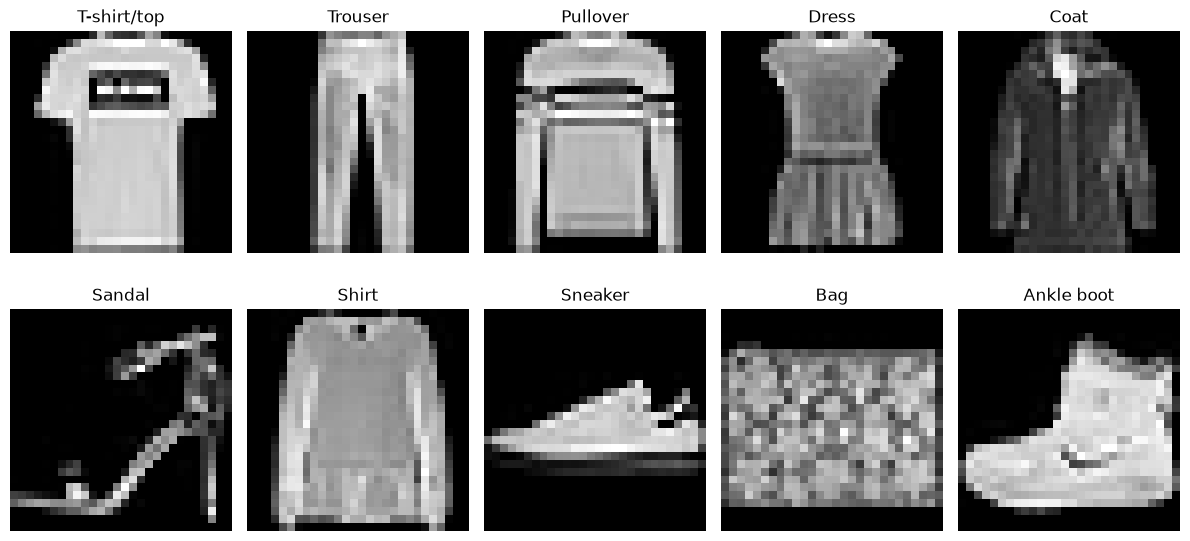

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for label, ax in enumerate(axes.flat):

    index = np.where(y_train == label)[0][0]

    ax.imshow(X_train[index], cmap="gray")
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

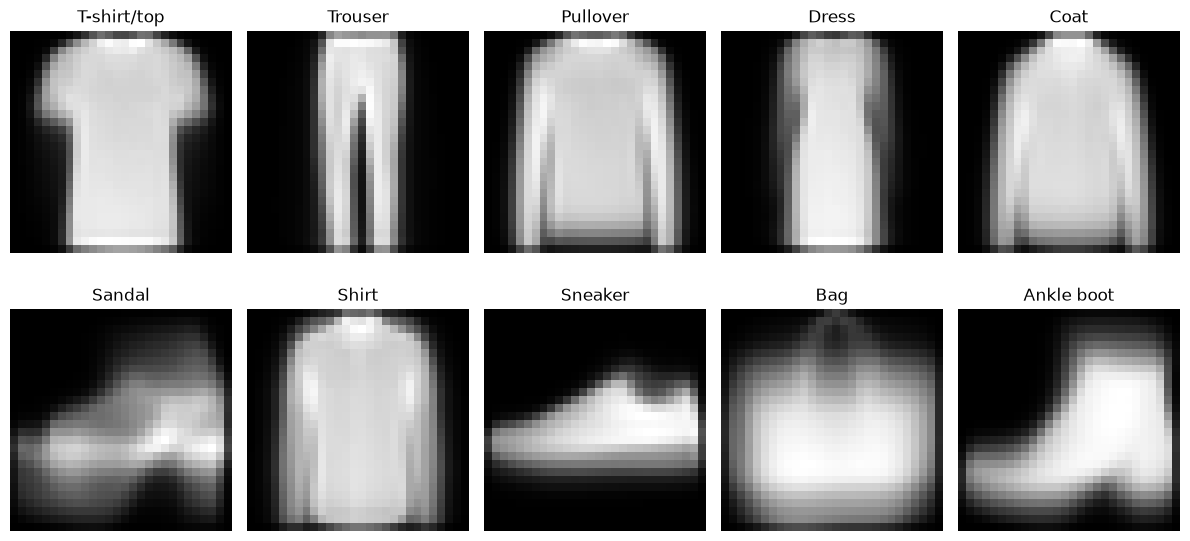

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for label, ax in enumerate(axes.flat):

    class_images = X_train[y_train == label]

    mean_image = class_images.mean(axis=0)

    ax.imshow(mean_image, cmap="gray")
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

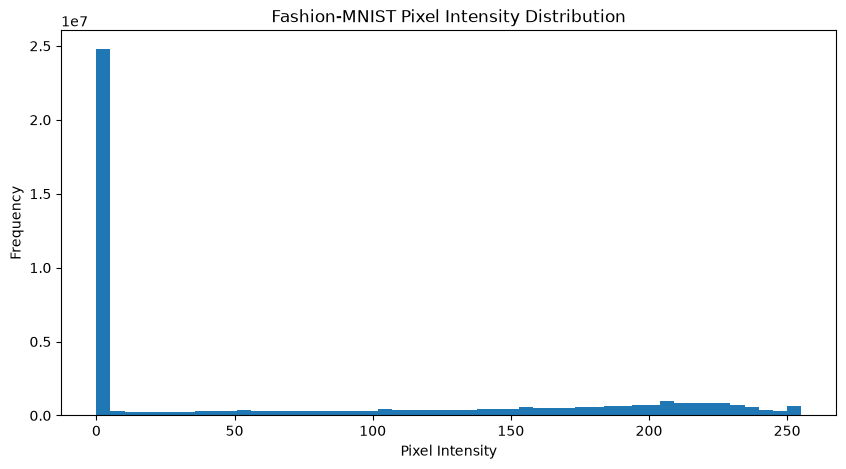

In [8]:
plt.figure(figsize=(10, 5))

plt.hist(
    X_train.ravel(),
    bins=50
)

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Fashion-MNIST Pixel Intensity Distribution")

plt.show()